<a href="https://colab.research.google.com/github/mvarboledar-rgb/developer-survey-analysis/blob/main/analysis/developer_survey_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What Shapes Developer Pay and Work in 2024?
### An analysis of the Stack Overflow Developer Survey (65,437 respondents, 185 countries)

**Author:** Manuela V. Arboleda Restrepo · Marketing professional & data analyst

**Business question:** If you were hiring, training or marketing to developers, what should you know about
where they work, how they are paid and which tools they want to learn next?

**What this notebook does**
1. Audits data quality and documents every cleaning decision
2. Profiles who answered the survey
3. Compares work models (remote, hybrid, in-person) and their link to pay
4. Measures demand for languages, databases and AI tools
5. Tests whether experience predicts job satisfaction
6. Summarizes findings and recommendations

> This project started as the IBM Data Analyst Professional Certificate capstone. I rebuilt it as a single,
> reproducible analysis and revised one method from the course version (see *Cleaning decisions*).

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
            "n01PQ9pSmiRX6520flujwQ/survey-data.csv")
LOCAL_FILE = Path("../data/survey-data.csv")   # used if you download the file first
IMG_DIR = Path("../images"); IMG_DIR.mkdir(exist_ok=True)

# One accent color for the point of each chart, grey for context
ACCENT, ACCENT_2, GREY = "#1f6f8b", "#e07a5f", "#b8c2c7"
sns.set_theme(style="white", font_scale=1.05)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110})

def save(fig, name):
    fig.savefig(IMG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

def explode_counts(series, top=None):
    """Count items in a semicolon-separated multi-select column."""
    s = series.dropna().str.split(";").explode().str.strip()
    counts = s.value_counts()
    return counts.head(top) if top else counts

## 2. Load the data

In [2]:
df_raw = pd.read_csv(LOCAL_FILE if LOCAL_FILE.exists() else DATA_URL, low_memory=False)
print(f"Rows: {len(df_raw):,} | Columns: {df_raw.shape[1]}")
df_raw.head(3)

Rows: 65,437 | Columns: 114


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN


## 3. Data quality audit
Before analyzing, I check duplicates and how many people actually answered the questions this analysis depends on.

In [3]:
key_cols = ["Country", "Age", "Employment", "RemoteWork", "YearsCodePro",
            "ConvertedCompYearly", "JobSat", "LanguageHaveWorkedWith", "LanguageWantToWorkWith"]
key_cols = [c for c in key_cols if c in df_raw.columns]

dupes = df_raw.duplicated().sum()
quality = (pd.DataFrame({"answered": df_raw[key_cols].notna().sum(),
                         "missing": df_raw[key_cols].isna().sum()})
             .assign(missing_pct=lambda t: (t.missing / len(df_raw) * 100).round(1))
             .sort_values("missing_pct", ascending=False))
print(f"Exact duplicate rows: {dupes}")
quality

Exact duplicate rows: 0


,answered,missing,missing_pct
ConvertedCompYearly,23435,42002,64.2
JobSat,29126,36311,55.5
YearsCodePro,51610,13827,21.1
RemoteWork,54806,10631,16.2
LanguageWantToWorkWith,55752,9685,14.8
Country,58930,6507,9.9
LanguageHaveWorkedWith,59745,5692,8.7
Age,65437,0,0.0
Employment,65437,0,0.0


### Cleaning decisions
- **Duplicates:** exact duplicate rows are removed.
- **Compensation and job satisfaction are *not* imputed.** About two thirds of respondents skipped the pay
  question and over half skipped satisfaction. Filling those gaps with the median (as in the course version)
  would make most people look identical and flatten every comparison, so each analysis uses only the people
  who answered that question, and the sample size is shown.
- **Pay outliers:** yearly pay is analyzed in USD between the 1st and 99th percentile, to drop typos
  (e.g. $1 or $16M) without removing real high earners.
- **Experience:** "Less than 1 year" → 0 and "More than 50 years" → 51 so the column can be used as a number.

In [4]:
df = df_raw.drop_duplicates().copy()

df["YearsCodePro_num"] = pd.to_numeric(
    df["YearsCodePro"].replace({"Less than 1 year": 0, "More than 50 years": 51}), errors="coerce")
df["JobSat"] = pd.to_numeric(df["JobSat"], errors="coerce")

pay = df["ConvertedCompYearly"]
lo, hi = pay.quantile([0.01, 0.99])
df["Pay"] = pay.where(pay.between(lo, hi))

age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]
df["AgeGroup"] = pd.Categorical(df["Age"].where(df["Age"].isin(age_order)), categories=age_order, ordered=True)
df["WorkModel"] = df["RemoteWork"].replace({"Hybrid (some remote, some in-person)": "Hybrid"})

print(f"Rows after removing duplicates: {len(df):,}")
print(f"Respondents with usable pay data: {df['Pay'].notna().sum():,} (kept ${lo:,.0f}–${hi:,.0f})")

Rows after removing duplicates: 65,437
Respondents with usable pay data: 22,965 (kept $208–$393,751)


## 4. Who answered the survey?

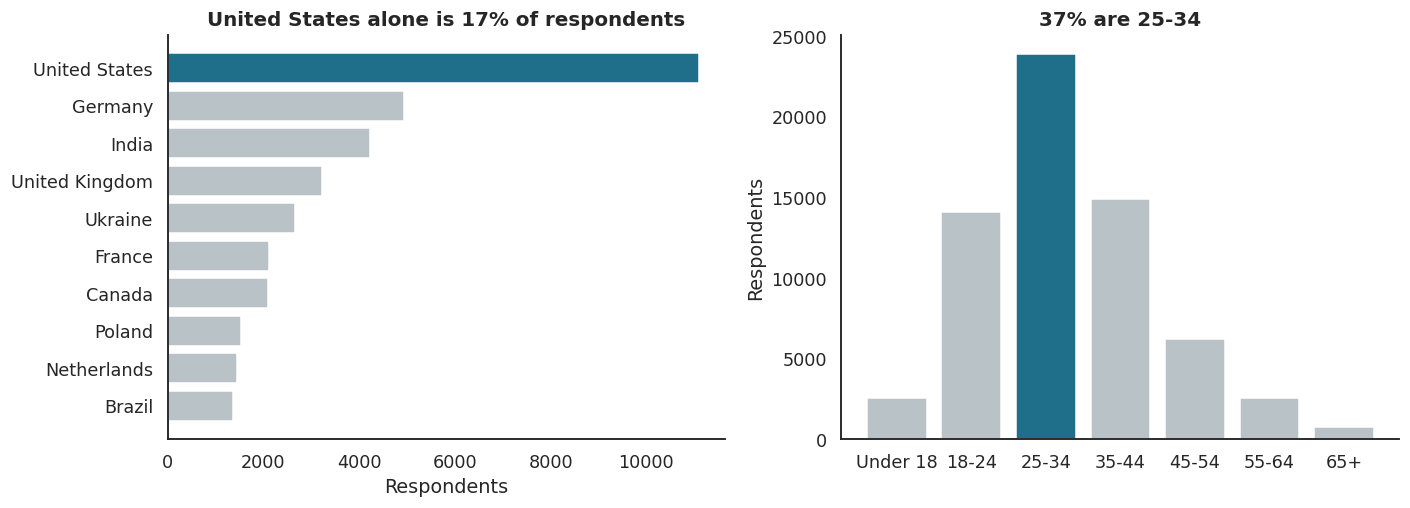

Countries represented: 185


In [5]:
countries = df["Country"].value_counts()
top10 = countries.head(10).sort_values()
labels = top10.index.str.replace("United Kingdom of Great Britain and Northern Ireland", "United Kingdom") \
                    .str.replace("United States of America", "United States")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = [ACCENT if i == len(top10) - 1 else GREY for i in range(len(top10))]
axes[0].barh(labels, top10.values, color=colors)
top_name = labels[-1]
axes[0].set_title(f"{top_name} alone is {countries.iloc[0] / len(df):.0%} of respondents")
axes[0].set_xlabel("Respondents")

ages = df["AgeGroup"].value_counts().reindex(age_order)
peak = ages.idxmax()
axes[1].bar(ages.index.str.replace(" years old", "").str.replace(" years or older", "+"), ages.values,
            color=[ACCENT if a == peak else GREY for a in ages.index])
axes[1].set_title(f"{ages.max() / ages.sum():.0%} are {peak.replace(' years old', '')}")
axes[1].set_ylabel("Respondents")
plt.tight_layout(); save(fig, "01_respondents"); plt.show()
print(f"Countries represented: {df['Country'].nunique()}")

## 5. Work model: remote, hybrid or in-person?

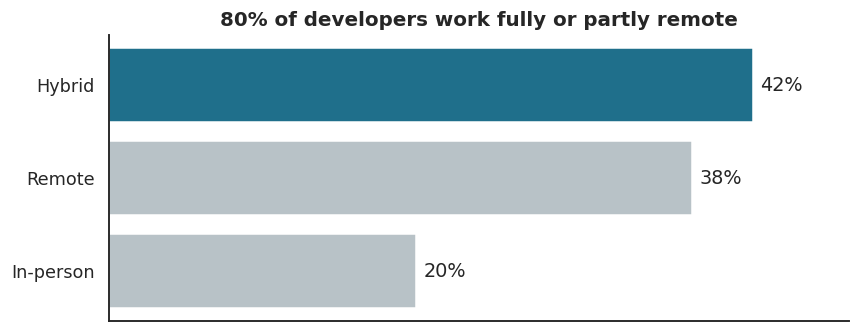

Based on 54,806 respondents who answered


In [6]:
wm = df["WorkModel"].value_counts()
wm_pct = wm / wm.sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(wm_pct.index[::-1], wm_pct.values[::-1],
        color=[ACCENT if i == 0 else GREY for i in range(len(wm))][::-1])
for i, v in enumerate(wm_pct.values[::-1]):
    ax.text(v + 0.005, i, f"{v:.0%}", va="center")
ax.set_xlim(0, wm_pct.max() * 1.15); ax.set_xticks([])
remote_share = wm_pct.get("Remote", 0) + wm_pct.get("Hybrid", 0)
ax.set_title(f"{remote_share:.0%} of developers work fully or partly remote")
plt.tight_layout(); save(fig, "02_work_model"); plt.show()
print(f"Based on {wm.sum():,} respondents who answered")

## 6. Pay
Medians are used instead of averages because pay is heavily skewed by a small number of very high earners.

Median yearly pay: $65,000 | middle 50%: $33,758–$107,406 | n = 22,965


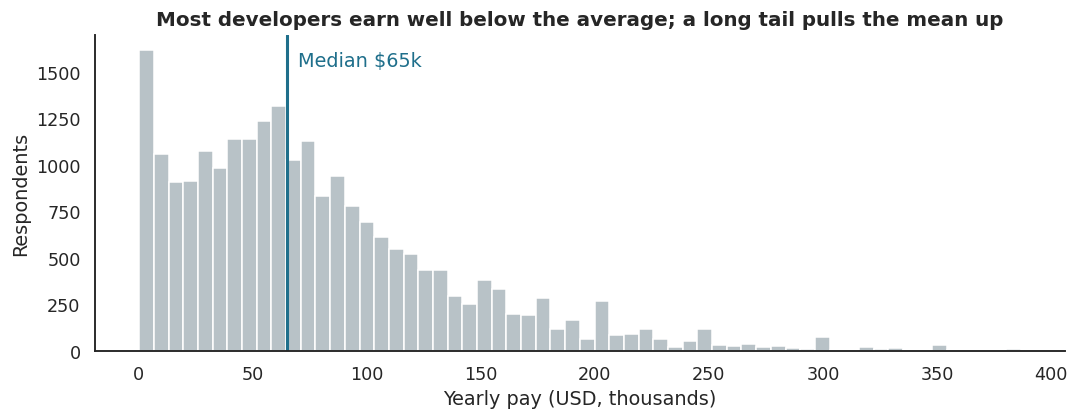

In [7]:
p = df["Pay"].dropna()
print(f"Median yearly pay: ${p.median():,.0f} | middle 50%: ${p.quantile(.25):,.0f}–${p.quantile(.75):,.0f} "
      f"| n = {len(p):,}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(p / 1000, bins=60, color=GREY)
ax.axvline(p.median() / 1000, color=ACCENT, lw=2)
ax.text(p.median() / 1000 + 5, ax.get_ylim()[1] * 0.9, f"Median ${p.median()/1000:,.0f}k", color=ACCENT)
ax.set_xlabel("Yearly pay (USD, thousands)"); ax.set_ylabel("Respondents")
ax.set_title("Most developers earn well below the average; a long tail pulls the mean up")
plt.tight_layout(); save(fig, "03_pay_distribution"); plt.show()

### Does working remotely go with higher pay?

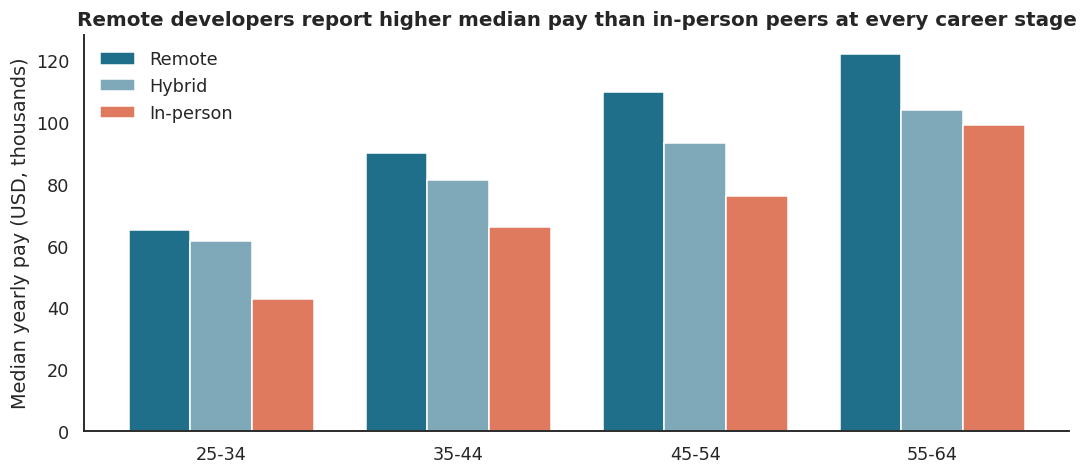

WorkModel,Remote,Hybrid,In-person
AgeGroup,,,
25-34 years old,65.3,61.9,43.0
35-44 years old,90.2,81.4,66.2
45-54 years old,110.0,93.4,76.3
55-64 years old,122.4,104.2,99.4


In [8]:
groups = ["25-34 years old", "35-44 years old", "45-54 years old", "55-64 years old"]
models = ["Remote", "Hybrid", "In-person"]
pay_wm = (df[df["AgeGroup"].isin(groups) & df["WorkModel"].isin(models)]
          .groupby(["AgeGroup", "WorkModel"], observed=True)["Pay"].median().unstack()[models]
          .reindex(groups))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(groups)); w = 0.26
for i, (m, c) in enumerate(zip(models, [ACCENT, "#7fa9b8", ACCENT_2])):
    ax.bar(x + (i - 1) * w, pay_wm[m] / 1000, w, label=m, color=c)
ax.set_xticks(x, [g.replace(" years old", "") for g in groups])
ax.set_ylabel("Median yearly pay (USD, thousands)"); ax.legend(frameon=False)
if (pay_wm["Remote"] > pay_wm["In-person"]).all():
    ax.set_title("Remote developers report higher median pay than in-person peers at every career stage")
else:
    ax.set_title("Median pay by age group and work model")
plt.tight_layout(); save(fig, "04_pay_by_work_model"); plt.show()
(pay_wm / 1000).round(1)

**Check: is this just a country effect?** Countries with higher salaries (like the US) may also have more remote
work. Repeating the comparison inside a single country removes most of that effect.

In [9]:
us = df[df["Country"] == "United States of America"]
us_wm = us[us["WorkModel"].isin(models)].groupby("WorkModel")["Pay"].agg(["median", "count"]).reindex(models)
us_wm["median"] = us_wm["median"].round(-3)
us_wm

,median,count
WorkModel,,
Remote,150000.0,2351
Hybrid,130000.0,1540
In-person,102000.0,621


## 7. Technology demand: what developers use vs. what they want to learn

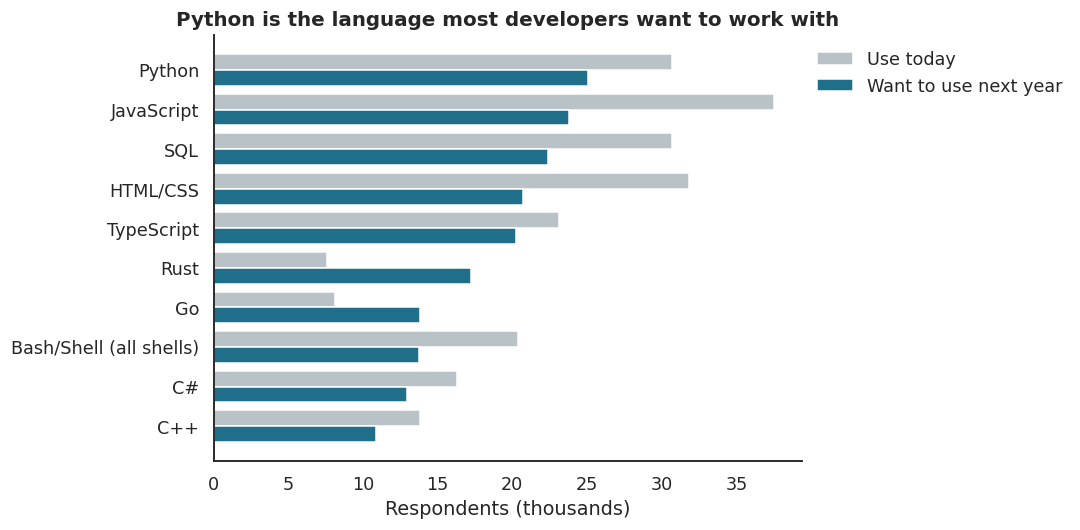

,Use today,Want to use,Interest gap
LanguageWantToWorkWith,,,
Rust,7559,17232,9673
Go,8103,13837,5734
TypeScript,23150,20239,-2911
C++,13827,10873,-2954
C#,16318,12921,-3397
Python,30719,25047,-5672
Bash/Shell (all shells),20412,13744,-6668
SQL,30682,22400,-8282
HTML/CSS,31816,20721,-11095


In [10]:
used = explode_counts(df["LanguageHaveWorkedWith"])
wanted = explode_counts(df["LanguageWantToWorkWith"])
top_lang = wanted.head(10).index
lang = pd.DataFrame({"Use today": used.reindex(top_lang), "Want to use": wanted.reindex(top_lang)})
lang = lang.sort_values("Want to use")

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(lang))
ax.barh(y + 0.2, lang["Use today"] / 1000, 0.4, color=GREY, label="Use today")
ax.barh(y - 0.2, lang["Want to use"] / 1000, 0.4, color=ACCENT, label="Want to use next year")
ax.set_yticks(y, lang.index); ax.set_xlabel("Respondents (thousands)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"{lang['Want to use'].idxmax()} is the language most developers want to work with")
plt.tight_layout(); save(fig, "05_languages"); plt.show()

lang["Interest gap"] = lang["Want to use"] - lang["Use today"]
lang.sort_values("Interest gap", ascending=False)

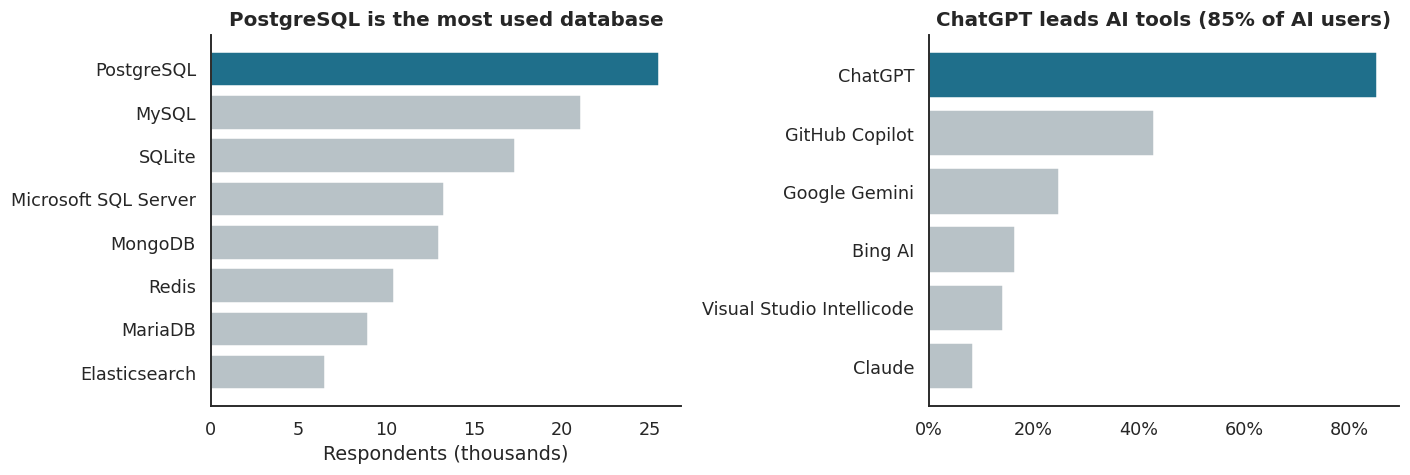

In [11]:
dbs = explode_counts(df["DatabaseHaveWorkedWith"], top=8).sort_values()
ai_col = next((c for c in ["AISearchDevHaveWorkedWith", "AIToolCurrently Using"] if c in df.columns), None)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(dbs.index, dbs.values / 1000, color=[ACCENT if i == len(dbs) - 1 else GREY for i in range(len(dbs))])
axes[0].set_title(f"{dbs.idxmax()} is the most used database"); axes[0].set_xlabel("Respondents (thousands)")
if ai_col:
    ai = explode_counts(df[ai_col], top=6).sort_values()
    users = df[ai_col].notna().sum()
    axes[1].barh(ai.index, ai.values / users, color=[ACCENT if i == len(ai) - 1 else GREY for i in range(len(ai))])
    axes[1].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    axes[1].set_title(f"{ai.idxmax()} leads AI tools ({ai.max() / users:.0%} of AI users)")
plt.tight_layout(); save(fig, "06_databases_ai"); plt.show()

## 8. Does experience predict job satisfaction?

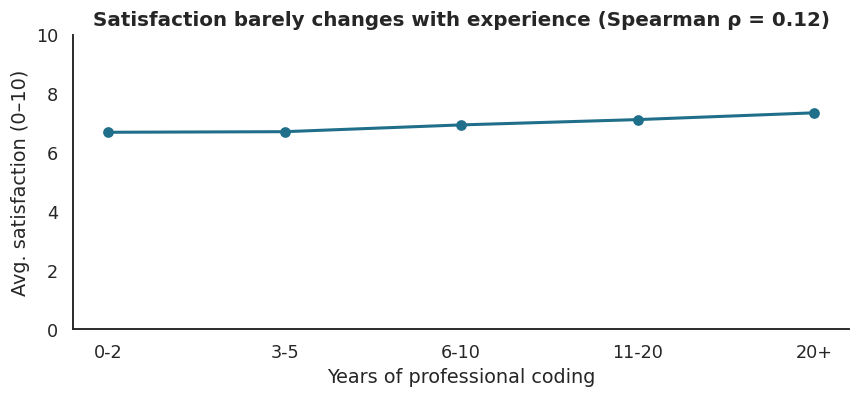

n = 28,356 respondents who answered both questions


,mean,count
Experience,,
0-2,6.69,4106
3-5,6.71,6143
6-10,6.94,7737
11-20,7.12,6899
20+,7.35,3471


In [12]:
sat = df[["YearsCodePro_num", "JobSat"]].dropna()
rho = sat.corr(method="spearman").iloc[0, 1]
sat["Experience"] = pd.cut(sat["YearsCodePro_num"], [-1, 2, 5, 10, 20, 60],
                           labels=["0-2", "3-5", "6-10", "11-20", "20+"])
by_exp = sat.groupby("Experience", observed=True)["JobSat"].agg(["mean", "count"]).round(2)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(by_exp.index.astype(str), by_exp["mean"], marker="o", color=ACCENT, lw=2)
ax.set_ylim(0, 10); ax.set_xlabel("Years of professional coding"); ax.set_ylabel("Avg. satisfaction (0–10)")
ax.set_title(f"Satisfaction barely changes with experience (Spearman ρ = {rho:.2f})")
plt.tight_layout(); save(fig, "07_satisfaction"); plt.show()
print(f"n = {len(sat):,} respondents who answered both questions")
by_exp

## 9. Key findings

In [13]:
remote_gap = (pay_wm["Remote"] / pay_wm["In-person"] - 1)
gap_text = (f"Remote developers report {remote_gap.min():.0%}–{remote_gap.max():.0%} higher median pay than in-person peers aged 25–64."
            if (remote_gap > 0).all() else
            f"The remote vs. in-person pay gap ranges from {remote_gap.min():+.0%} to {remote_gap.max():+.0%} across age groups 25–64.")
findings = [
    f"{remote_share:.0%} of developers work fully or partly remote; only {wm_pct.get('In-person', 0):.0%} are fully in-person.",
    f"Median yearly pay is ${p.median():,.0f}; the middle half earns ${p.quantile(.25):,.0f}–${p.quantile(.75):,.0f}.",
    gap_text,
    f"{wanted.index[0]}, {wanted.index[1]} and {wanted.index[2]} are the languages developers most want to use next.",
    f"{dbs.idxmax()} is the most used database.",
    (f"Experience is almost unrelated to job satisfaction (Spearman ρ = {rho:.2f})." if abs(rho) < 0.2
     else f"Experience and job satisfaction are correlated (Spearman ρ = {rho:.2f})."),
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. 80% of developers work fully or partly remote; only 20% are fully in-person.
2. Median yearly pay is $65,000; the middle half earns $33,758–$107,406.
3. Remote developers report 23%–52% higher median pay than in-person peers aged 25–64.
4. Python, JavaScript and SQL are the languages developers most want to use next.
5. PostgreSQL is the most used database.
6. Experience is almost unrelated to job satisfaction (Spearman ρ = 0.12).


## 10. Recommendations
- **Hiring:** offering remote or hybrid work is now the norm, not a perk. In-person-only roles compete for a
  smaller share of candidates.
- **Training and marketing to developers:** focus content on the languages with the biggest gap between
  current use and interest; that is where demand for learning is.
- **Retention:** seniority alone does not raise satisfaction, so retention plans should look at other drivers
  (pay, tools, work model) rather than tenure.

## Limitations
- The survey is voluntary and over-represents some countries (especially the US and Europe).
- Pay is self-reported and converted to USD; the remote-pay link is a correlation, not proof that remote work
  causes higher pay.